# Benchmark Analysis

This notebook reads the CSV files produced by the benchmark scripts in `benchmarks/` and turns them into the tables and figures of the experimental chapter.

It performs **no computation**: the runs are done once by the scripts, and this notebook only loads and presents their output. Run the scripts first:

```
python benchmarks/computation_time.py
python benchmarks/memory_usage.py
python benchmarks/effect_geometry.py
python benchmarks/effect_filtration_scope.py
```

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from persistent_homology.plotting import plot_loglog_time

RESULTS = '../benchmarks/results'
FIGURES = '../figures'

## 2. Computation Time

Wall-clock time on the noisy circle as the number of points grows.

In [2]:
time_df = pd.read_csv(f'{RESULTS}/computation_time.csv')
exp_df = pd.read_csv(f'{RESULTS}/scaling_exponents.csv')
exponents = dict(zip(exp_df['method'], exp_df['exponent']))

time_table = time_df.pivot(index='method', columns='n',
                           values='time_s')
time_table

n,30,50,75,100,200,500
method,,,,,,
GUDHI,0.006985,0.050982,0.378765,1.051998,27.086182,NaN
Ripser,0.002530,0.009302,0.033282,0.082572,0.661897,12.432065
our_clearing,0.329238,2.959859,20.408852,114.852495,NaN,NaN
our_cohomology,0.146746,1.009913,6.591358,19.532561,NaN,NaN
our_standard,0.352003,3.114548,20.894616,119.647210,NaN,NaN


Saved -> ../figures/loglog_circle.png


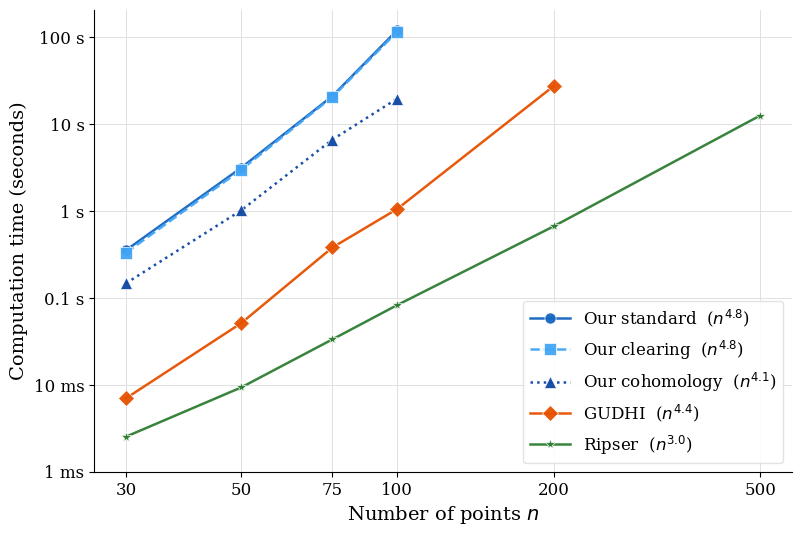

In [3]:
# Log-log plot of time versus number of points
ax = plot_loglog_time(time_df, exponents=exponents, title='', #Computation time, noisy circle
                      savepath=f'{FIGURES}/loglog_circle.png')
plt.show()

## 3. Memory Usage

Peak memory of our three implementations (Python-level allocations).

In [4]:
mem_df = pd.read_csv(f'{RESULTS}/memory_usage.csv')
mem_table = mem_df.pivot(index='method', columns='n',
                         values='peak_mb')
mem_table

n,30,50,75,100
method,,,,
our_clearing,11.308395,67.415070,357.036873,1086.741970
our_cohomology,19.375816,119.755066,709.344521,2018.004364
our_standard,11.322489,67.474854,357.248901,1087.239319


## 4. Effect of Dataset Geometry

Computation time at fixed $n = 100$ and $\varepsilon_{\max} = 2$, across the four geometries.

In [ ]:
geom_df = pd.read_csv(f'{RESULTS}/effect_geometry.csv')
geom_table = geom_df.pivot(index='method', columns='dataset',
                           values='time_s')
geom_table

## 5. Effect of the Filtration Scope

Computation time at fixed $n = 100$ on the circle, as $\varepsilon_{\max}$ grows.

In [ ]:
scope_df = pd.read_csv(f'{RESULTS}/effect_filtration_scope.csv')
scope_table = scope_df.pivot(index='method', columns='max_eps',
                             values='time_s')
scope_table

In [ ]:
# Number of persistence pairs, and cohomology speedup over standard
pairs_table = scope_df.pivot(index='method', columns='max_eps',
                             values='pairs')
print('Persistence pairs by max_eps:')
print(pairs_table.loc[['our_standard']].to_string())

speedup = (scope_table.loc['our_standard']
           / scope_table.loc['our_cohomology'])
print('\nCohomology speedup over standard:')
for eps, s in speedup.items():
    print(f'  max_eps = {eps}: {s:.2f}x')